# RT-DETR

Para el environments usar el fichero requirements.txt de https://github.com/lyuwenyu/RT-DETR/tree/main/rtdetrv2_pytorch. No requiere de ninguna librería propioa

In [1]:
import os, sys, subprocess, urllib.request
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import cv2
import numpy as np
import torch
from PIL import Image
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

REPO = "RT-DETR/rtdetrv2_pytorch"
# Clona el repo oficial de RT-DETR si no existe y lo añade al path.

if not os.path.exists("RT-DETR"):
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/lyuwenyu/RT-DETR.git"], check=True)
sys.path.insert(0, os.path.abspath("RT-DETR/rtdetrv2_pytorch"))

# Ahora podemos cargar los módulos necesarios.


from src.data.dataset import mscoco_category2name, mscoco_label2category

# Los nombres de las clases vienen del dataset COCO, usado en el entrenamiento del modelo.
CLASS_NAMES = {lab: mscoco_category2name[cat] for lab, cat in mscoco_label2category.items()}  # 0..79
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Mostramos las clases. Como se puede ver, son las mismas que las de YOLO.

print (CLASS_NAMES)

{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard', 67: 'cell phone', 68: 'microw

In [2]:
from load_rtdetr import load_rtdetr
# Se puede elegir cualquier familia v1 o v2 y tamaño: s, m, l y x.
model, postprocessor = load_rtdetr(family="v2", size="l", device=DEVICE)

@torch.no_grad()
def detect(bgr, conf=0.6):
    
    h, w = bgr.shape[:2]
    im = Image.fromarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)).resize((640, 640), Image.BILINEAR)
    x = torch.from_numpy(np.array(im)).permute(2, 0, 1).float().div(255)[None].to(DEVICE)
    labels, boxes, scores = postprocessor(model(x), torch.tensor([[w, h]], device=DEVICE))
    labels, boxes, scores = labels[0].cpu().numpy(), boxes[0].cpu().numpy(), scores[0].cpu().numpy()
    keep = scores >= conf  
    return boxes[keep], scores[keep], labels[keep]

Cargando RT-DETR familia 'v2', tamaño 'l' en cuda
Load PResNet50 state_dict


(np.float64(-0.5), np.float64(1074.5), np.float64(581.5), np.float64(-0.5))

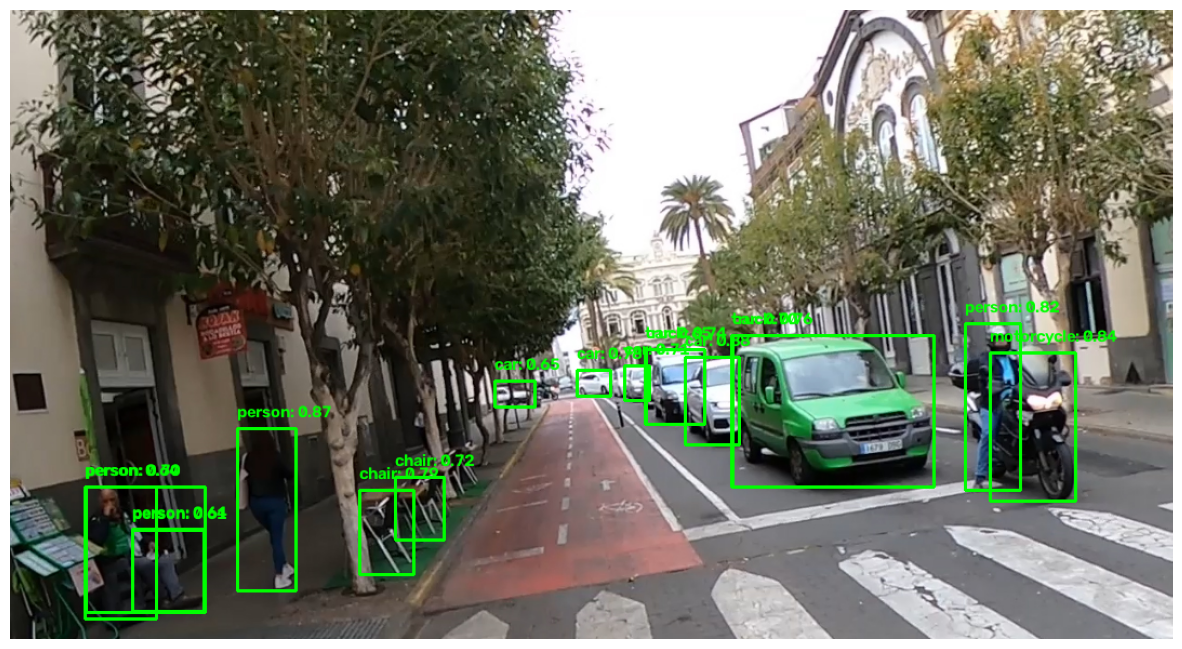

In [3]:
# Ejemplo de uso con imagen estática.

path_test = 'test.jpg'
image = cv2.imread(path_test)

boxes, scores, labels = detect(image, conf=0.6)

for box, score, label in zip(boxes, scores, labels):
    x1, y1, x2, y2 = box.astype(int)
    cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(image, f"{CLASS_NAMES[label]}: {score:.2f}", (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
    
plt.figure(figsize=(15, 10))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis('off')



In [4]:
# Ejemplo de uso parecido al de YOLO. Detectar entrada desde la webcam.

vid = cv2.VideoCapture('C0142.MP4')
#vid = cv2.VideoCapture(0)
while True:
    ret, img = vid.read()

    if ret:
        boxes, scores, labels = detect(img, conf=0.4)

        for (x1, y1, x2, y2), score, cls in zip(boxes, scores, labels):
            color = tuple(int(c) for c in np.random.RandomState(int(cls)).randint(50, 255, 3))  # BGR
            cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), color, 3)
            cv2.putText(img, f"{CLASS_NAMES[int(cls)]} {score:.2f}", (int(x1), max(int(y1) - 8, 20)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2)

        cv2.imshow("Vid", img)
        if cv2.waitKey(20) == 27:
            break

vid.release()
cv2.destroyAllWindows()

## Fase 1. Datos

Preparación del dataset propio de matrículas para entrenar RT-DETR.

- **Origen**: `C:\Uni\VC\Dataset\images` y `C:\Uni\VC\Dataset\annotations`. Cada anotación es un JSON con una lista de matrículas: `rectangle` = `[cx, cy, w, h]` normalizado (estilo YOLO) y `plate` = texto (`"None"` si es ilegible).
- **Orientación**: las cajas están anotadas sobre la imagen ya girada según su EXIF (300 fotos tienen orientación 6), así que se aplica la rotación EXIF antes de reescalar.
- **Salida**: `C:\Uni\VC\Dataset_coco` con las imágenes reescaladas (lado mayor 1280 px, sin ampliar las pequeñas) y un JSON COCO por conjunto.
- **Una sola clase** (`matricula`, `category_id = 0`, porque RT-DETR usa el id directamente como etiqueta cuando no se remapean las categorías de COCO).
- **Para el OCR** se conservan en cada anotación: `segmentation` (polígono de 4 esquinas derivado de la caja, ya que el dataset no trae polígono), `text` (`None` si es ilegible) y `chars` (lista de caracteres del texto).
- Las matrículas ilegibles cuentan para el detector; para el OCR se descartan (`legible = False`).
- `20261031_174251.jpg` no tiene anotación y se excluye.

In [5]:
import json, random
from pathlib import Path
from collections import Counter
from PIL import Image, ImageOps


DATASET_DIR = Path(r"C:\Uni\VC\Dataset")
IMG_DIR     = DATASET_DIR / "images"
ANN_DIR     = DATASET_DIR / "annotations"

OUT_DIR     = Path(r"C:\Uni\VC\P4\Dataset_coco")
OUT_IMG_DIR = OUT_DIR / "images"
OUT_ANN_DIR = OUT_DIR / "annotations"

MAX_SIDE = 1280                                        # lado mayor tras reescalar
BLOCK    = 10                                          # fotos seguidas que van juntas al mismo conjunto
SPLITS   = {"train": 0.60, "val": 0.15, "test": 0.25}
SEED     = 42

CATEGORIES = [{"id": 0, "name": "matricula", "supercategory": "vehiculo"}]
IMG_EXTS   = {".jpg", ".jpeg", ".png"}

### 1. Reescalar y convertir a COCO

In [6]:
def rect_to_xyxy(rect, W, H):
    """[cx, cy, w, h] normalizado -> esquinas en píxeles, recortadas a la imagen."""
    cx, cy, w, h = rect
    x1 = max(0.0, (cx - w / 2) * W)
    y1 = max(0.0, (cy - h / 2) * H)
    x2 = min(float(W), (cx + w / 2) * W)
    y2 = min(float(H), (cy + h / 2) * H)
    return x1, y1, x2, y2


def load_resized(path):
    """Abre la imagen, aplica la rotación EXIF y reduce el lado mayor a MAX_SIDE (no amplía)."""
    im = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    W, H = im.size
    scale = min(1.0, MAX_SIDE / max(W, H))
    if scale < 1.0:
        im = im.resize((round(W * scale), round(H * scale)), Image.LANCZOS)
    return im


OUT_IMG_DIR.mkdir(parents=True, exist_ok=True)
OUT_ANN_DIR.mkdir(parents=True, exist_ok=True)

coco_images, coco_anns = [], []
sin_anotacion, cajas_degeneradas = [], 0

img_paths = sorted(p for p in IMG_DIR.iterdir() if p.suffix.lower() in IMG_EXTS)
for img_path in img_paths:
    ann_path = ANN_DIR / f"{img_path.stem}.json"
    if not ann_path.exists():
        sin_anotacion.append(img_path.name)
        continue

    out_name = f"{img_path.stem}.jpg"
    out_path = OUT_IMG_DIR / out_name
    if out_path.exists():                       # ya procesada en una ejecución anterior
        W, H = Image.open(out_path).size
    else:
        im = load_resized(img_path)
        im.save(out_path, quality=95)           # se guarda sin EXIF: la orientación ya está aplicada
        W, H = im.size

    img_id = len(coco_images)
    coco_images.append({"id": img_id, "file_name": out_name, "width": W, "height": H,
                        "orig_name": img_path.name})

    for obj in json.loads(ann_path.read_text(encoding="utf-8")):
        x1, y1, x2, y2 = rect_to_xyxy(obj["rectangle"], W, H)
        w, h = x2 - x1, y2 - y1
        if w < 1 or h < 1:
            cajas_degeneradas += 1
            continue
        plate   = obj.get("plate")
        bbox    = [round(v, 2) for v in (x1, y1, w, h)]
        legible = plate not in (None, "", "None")
        text    = plate.strip().upper() if legible else None
        coco_anns.append({
            "id": len(coco_anns),
            "image_id": img_id,
            "category_id": 0,
            "bbox": bbox,
            "area": round(bbox[2] * bbox[3], 2),    # área coherente con la caja redondeada
            "iscrowd": 0,
            "segmentation": [[round(v, 2) for v in (x1, y1, x2, y1, x2, y2, x1, y2)]],
            "text": text,
            "chars": list(text) if legible else [],
            "legible": legible,
        })

print(f"Imágenes convertidas: {len(coco_images)}")
print(f"Matrículas: {len(coco_anns)}  (legibles: {sum(a['legible'] for a in coco_anns)})")
print(f"Sin anotación (excluidas): {sin_anotacion}")
print(f"Cajas descartadas por tamaño < 1 px: {cajas_degeneradas}")
print("Tamaños más frecuentes:", Counter((i['width'], i['height']) for i in coco_images).most_common(5))

Imágenes convertidas: 1216
Matrículas: 2709  (legibles: 1628)
Sin anotación (excluidas): ['20261031_174251.jpg']
Cajas descartadas por tamaño < 1 px: 5
Tamaños más frecuentes: [((960, 1280), 465), ((1280, 960), 314), ((720, 1280), 268), ((1280, 720), 72), ((576, 1280), 25)]


### 2. División en train, val y test

Las imágenes se ordenan por nombre y se agrupan en bloques de 10 fotos seguidas. Los bloques se barajan con semilla fija y se asignan enteros a cada conjunto (60 % train, 15 % val, 25 % test), de modo que fotos consecutivas del mismo coche no queden repartidas entre conjuntos.

In [7]:
blocks = [coco_images[i:i + BLOCK] for i in range(0, len(coco_images), BLOCK)]
order = list(range(len(blocks)))
random.Random(SEED).shuffle(order)

n_total = len(coco_images)
limits  = {"train": SPLITS["train"] * n_total,
           "val":   (SPLITS["train"] + SPLITS["val"]) * n_total}

split_of_img, assigned = {}, 0
for b in order:
    split = "train" if assigned < limits["train"] else "val" if assigned < limits["val"] else "test"
    for img in blocks[b]:
        split_of_img[img["id"]] = split
    assigned += len(blocks[b])

coco_splits = {}
for split in SPLITS:
    imgs = [i for i in coco_images if split_of_img[i["id"]] == split]
    ids  = {i["id"] for i in imgs}
    anns = [a for a in coco_anns if a["image_id"] in ids]
    coco_splits[split] = {
        "info": {"description": f"Matrículas - {split}", "max_side": MAX_SIDE, "seed": SEED, "block": BLOCK},
        "images": imgs,
        "annotations": anns,
        "categories": CATEGORIES,
    }
    (OUT_ANN_DIR / f"instances_{split}.json").write_text(json.dumps(coco_splits[split], ensure_ascii=False),
                                                         encoding="utf-8")

# Carpeta de imágenes propia para cada conjunto (copias de OUT_IMG_DIR)
import shutil
for split, d in coco_splits.items():
    split_dir = OUT_DIR / f"images_{split}"
    split_dir.mkdir(exist_ok=True)
    for img in d["images"]:
        dst = split_dir / img["file_name"]
        if not dst.exists():
            shutil.copy2(OUT_IMG_DIR / img["file_name"], dst)

# Comprobación: cada bloque cae entero en un único conjunto
assert all(len({split_of_img[i["id"]] for i in blk}) == 1 for blk in blocks)

print(f"{'conjunto':<6} {'imágenes':>9} {'%':>6} {'matrículas':>11} {'legibles':>9}")
for split, d in coco_splits.items():
    n_img = len(d["images"])
    print(f"{split:<6} {n_img:>9} {100 * n_img / n_total:>5.1f}% {len(d['annotations']):>11} "
          f"{sum(a['legible'] for a in d['annotations']):>9}")
print(f"\nJSON guardados en {OUT_ANN_DIR}")

conjunto  imágenes      %  matrículas  legibles
train        736  60.5%        1535      1005
val          180  14.8%         417       238
test         300  24.7%         757       385

JSON guardados en C:\Uni\VC\P4\Dataset_coco\annotations


### 3. Visualización de anotaciones en train

Caja en verde, polígono en rojo y el texto encima (`?` si la matrícula es ilegible).

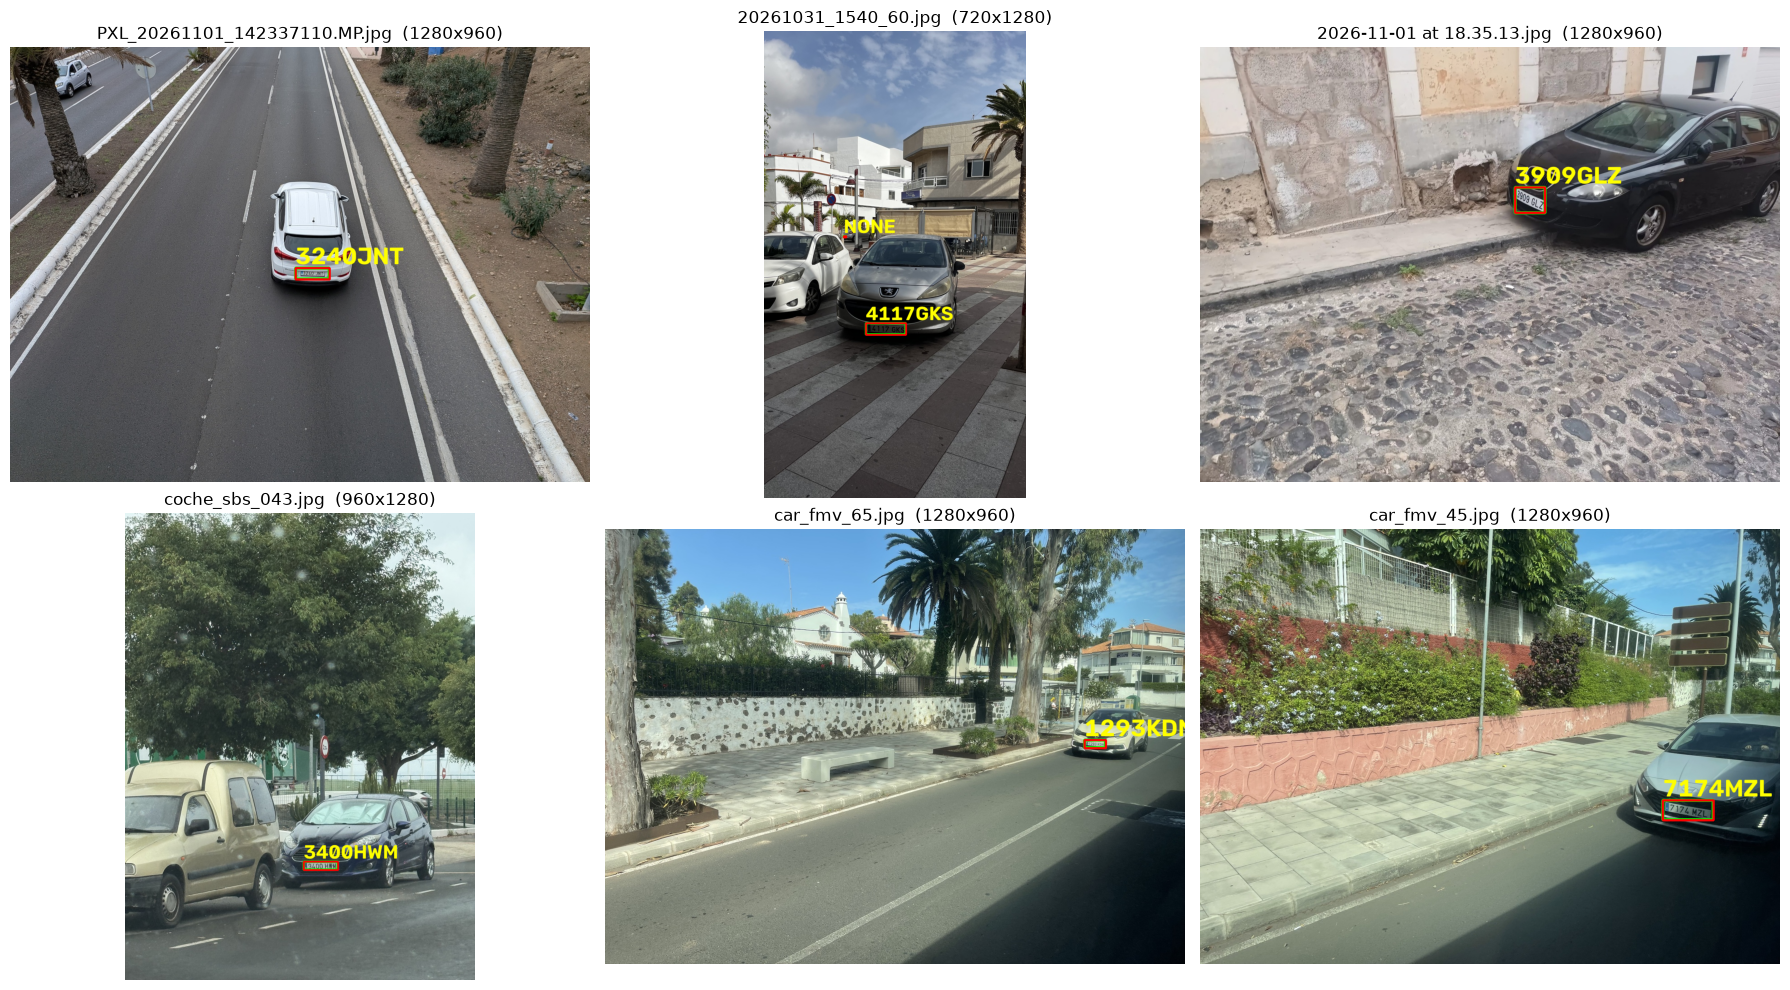

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def draw_annotations(coco, img_info):
    img  = cv2.cvtColor(cv2.imread(str(OUT_IMG_DIR / img_info["file_name"])), cv2.COLOR_BGR2RGB)
    lw   = max(2, round(max(img.shape[:2]) / 400))
    for a in (a for a in coco["annotations"] if a["image_id"] == img_info["id"]):
        x, y, w, h = map(int, a["bbox"])
        cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), lw + 2)
        poly = np.array(a["segmentation"][0], dtype=np.int32).reshape(-1, 2)
        cv2.polylines(img, [poly], isClosed=True, color=(255, 0, 0), thickness=lw)
        cv2.putText(img, a["text"] or "?", (x, max(y - 8, 20)), cv2.FONT_HERSHEY_SIMPLEX,
                    0.6 * lw, (255, 255, 0), lw)
    return img

train = coco_splits["train"]
con_matricula = sorted({a["image_id"] for a in train["annotations"]})
muestra = random.Random(SEED).sample(con_matricula, 6)
info_by_id = {i["id"]: i for i in train["images"]}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, img_id in zip(axes.ravel(), muestra):
    info = info_by_id[img_id]
    ax.imshow(draw_annotations(train, info))
    ax.set_title(f"{info['file_name']}  ({info['width']}x{info['height']})")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Fase 2. Configuración del entrenamiento para el modelo de matrículas

Creada carpeta **config** con los ficheros:
- **coco_detection.yml** -> Establece el nº de clases, directorio de anotaciones e imágenes train y val y el evaluador
- **rtdetrv2_r18vd_120e_coco.yml** -> Características del modelo, nº de epocas, lr, data augmentation y entre otros


### Características varias
- Data Augmentation, con `RandomPhotometricDistort`,  `RandomZoomOut`, `RandomZoomIn`, `Resize` y entre otros...
- Exponential Moving Average (EMA) da más prioridad a los pesos actuales y menos a los antiguos
- 50 épocas
- ResNet de 18 capas + 3 capas de decoder. Modelo **RT-DETRV2-S**, con los pesos originales
- Batch de 16 elementos
- Optimizador AdamW
- El nº de clases se ha reducido a 1, sólo matrículas
<br><br>

## Fase 3. Ejecución del entrenamiento

Para llevar a cabo el entrenamiento, se debe ejecutar este comando en el environment de conda:

```bash 
python RT-DETR/rtdetrv2_pytorch/tools/train.py -c configs/rtdetrv2_r18vd_120e_coco.yml --use-amp --seed 0
```

Al usar imágenes de 640x640, con batch de 16 items, y un modelo con 18 capas, tiende a tardar y a consumir mucha VRAM/RAM. En este caso, con la configuración establecida, con 8GB de VRAM, el entrenamiento debería tardar **1-2 horas**☠️